In [1]:
import requests
import pandas as pd
import time

# Ваши куки и заголовки оставляем без изменений
cookies = {
    'NSC_wtsw_obti.epn.sg_dzs_iuuqt': 'ffffffff09da1a3745525d5f4f58455e445a4a423660',
    'spid': '1793084984398_c5648e9c6b6edd72ce41e85da37fb356_af1em1v3f1amtkn4',
    '___dmpkit___': 'ffd9164d-ca2d-4eaf-a95a-8a304f4552e5',
    'portalGeo': '%7B%22regionCd%22%3A%2278%22%2C%22regionNm%22%3A%22%D0%A1%D0%B0%D0%BD%D0%BA%D1%82-%D0%9F%D0%B5%D1%82%D0%B5%D1%80%D0%B1%D1%83%D1%80%D0%B3%22%2C%22cityCd%22%3Anull%2C%22cityNm%22%3A%22%D0%A1%D0%B0%D0%BD%D0%BA%D1%82-%D0%9F%D0%B5%D1%82%D0%B5%D1%80%D0%B1%D1%83%D1%80%D0%B3%22%7D',
    'knSortSeed': '%7B%22filterKey%22%3A%22spnafv%22%2C%22sortField%22%3A%22default%22%2C%22sortSeed%22%3A2057873490%7D',
    'spjs': '1793089801309_25c877f6_0f8ee54c_d2d4345e593ebbcefe25ebadfea88d7e_bcLVk6FOThheWG141aJfEY2fvMRDAs9yo/9v8oOeYwPir59jko/ub3Puz7MDnmTjEq+/Y5IFD8Kj32/yCY9uw6MP7sPTD/5uw+7PwwOOz7MDnmBDAq+/Y5IF7/Kj32/yDa/Ow9MP/m0T3s+jA55qkqPfb/IJ797Dww/+ZoKvz2OCr89jgq/PY4Kvz2OCr89jgC1fQYXsjHCADLnFsInZgJDJ/ODADGnwwPnJxeXJrMWwifnAEo9eY4Gv7W8Cy89jA47v4gON7/cj723Cgd5twql//2OCrexg4AmpxcDsnID1rPxgsBx5gLXM+aXAnIn10JmsgKCs/m9jzU1TDY/+4vIPjePRLenwxbn85dDJucXAjKnFwPzJ8BXpzGCl6fygANyZ8BAM7MPjD+7jgg/sQYCcebXQ3KxlkNmsdcCZ3JDg/LylkNz8kOWpzIXV7OnwB63pwLDZuaCwHJyloJxsoOC8zHAQDNyA8BzMwOAZrIAFvPszg42r9oOaT4MDnu/yA45EQ7MCX/IkWzkUJRkpJZF8vQCBjWqVFWmpFPS96wbBjPzhYIxd5vUZDIDAPehg4M1955SI6SXW+bnHNRitENC8nQCw7e1nNwqrN0FN6SUVOb3n9dnZVXEd69UEqRk10Xz8sNFs7QCBbO3mtZmJ9KUdHLCw/QzQ4Yu5pfF8/LDRbO0AgWztw8MO7uMBLw9jktzc0LB+P+OLiB3jgK+6lRVs3MAhn0/EpN7PxKTez8XVbs+11W07l6KvubVhWrrSo9jIsVaqu+OHLH9jgq+alRVpqRT0vk8HVRnYxXS5GYTBi7ml9d5PZ7UIyRVVGLkyIzsJFMEL/EekqfkFwa+2U5o//majz2/yg9pPwwOp7+Ui/Mzw0Jz88MDMzKCQ3MzAoMys8KCs/PCkj+hAAy/YYADuz8Dgze/hI4zPlvUZCaV0+NxD4Jx9AIFs68NQnLyxYI0MoKAM3QDgq2/mI/uptLU4qRSLr/9X9XkZlUXd63VlvQdjmu/2w5MPYEyLR8+ygIXP84kv/KMGzs+jA55tcqPvb/KDnm6yo+9v8oOOboKjz2/yAV7PowOebOKjz2/yAX7PwwOObiGDjW/og5/tyCOfT9OTj+7uQ83Og5O//8ODn6+jk5//84Ovz6Ojr8/gc71Ok4Of79OTj+/Ts7/v44OP3+Ozv+/Ts7/sw2MPDuMCDw3jAIXy335//ENDX+/jh46zP0dMHmOXr6n01Mkbw8VpGQXXr6n01Mkbw8VpGQXXL19jko/+Y4GGL7EDiswjk5//85Of//OTn//zk5//85Of/+ODn//zk5//85Of//OTn//zk4//85Of//OTj//zk5//85Of7/OTn+/hIB9jg6IP7cOzn//xI09v4oOOb+GDjW/gg4zv4CPPb+KDi+/nA4rv1gOJz2MDju/iA43v5QOIv+OLjBzEoyzvb8Ou78IDneOjoQ/s78Osb+eDi2/mg4pPtKTdOsbVj+ljhI/ob8On7/OLD//qg5+u7DO9zhMjW7i0pXjpsXdZGNW1eJ7D1Ki9NqbeT5ChWal19Ritb0xgEBx8cBAcc5zPEwOez6Ojr8/yAA2+M4xrzEcTLh9rg07h4+IH7yGIj41ClUn5BcS52fSF3TjkpRk59KQezoMLv07tw94/64prrbODjHuhC48s6IPuT1MCDu5iU4/l4HGP7e4Ty8Czoq6PQ9UZCKXVTs/iI9mZtWFcfcOBD+zigiOv8wOuztf1eRmVRd3rdWW9DeEHGQil1U1+RpebC5dH3e1nFWiptUFN63VkybkhBq195tcLref0qfjlBRnY0YEM6GCAjOzgF6ys8RGLqXSl2digt8z88YTo2hDWfO3khLoctnCNLefAu6zwkR3PJvXZy1UUzeqV1aubISPqmbWnOXigi4fv8AKL4Axzu2fhhqzaldWrmyGH+yrXQYu60YC9DOCBjWsUhdkLl0GLutGH+yrXQYu60YC9DOGHuWjFdVl4tVEabeGhjMmwsByZoLXsaaXQzKnQtZyZxaCJybAF2bnQkBnc0PANY0PgL3/zk5//85Of//elz0xCA4fn45uH7/uCh+7jzQ+fQwCO7uMDR+fjzEAQHHP378uDr2fri4fvYmuO7iMLj/frg6fva4ML4Bxzvs/CA45Os5Of//OTn//zg4//44OP7+ODj+/jgY/9Y1Cvn+ODj+/jg4tJkwGezuMLh+fogo7haksf3m6OU6/yoo9n64uE7uKIZfCTIgXHbdPeT0MJ1yP7gQ7lu0edauCj72/Sg75v944/iuxzmk8jA47v4gON7+EDjO/loy8x6Tv7rr9fS8vFDlaKRKPZiXVF3Erq3MT1HSC6P+GIm6niFS/owouD0Gc1qCRi9tpZcFLXNhdEKM9to+5KIwOO7+IDneKOHSSvoQKM72ACi06UpN0ptWFJuQFX+80l1W06trFIyLFWqrrD1vl5ALCqP+ODi+nuq1fHE2UAl27/70jqXgLnE3QN5+Obh+/7A57m45xgH9oDl+3ho7/v44EvTjyzxLvh04/v44uv/+sDn+; spsc=1793089801309_8755dff59e4c335f924df78f50b851f7_7p5fBpoMEdFeQQLD1Qvxf0TU7bFc2gdNVHHhTm1guC8Z',
}

headers = {
    'accept': 'application/json, text/plain, */*',
    'accept-language': 'ru,en;q=0.9,en-GB;q=0.8,en-US;q=0.7,ru-RU;q=0.6',
    'authorization': 'Basic MTpxd2U=',
    'priority': 'u=1, i',
    'referer': 'https://xn--80az8a.xn--d1aqf.xn--p1ai/%D0%BD%D0%BE%D0%B2%D0%BE%D1%81%D1%82%D1%80%D0%BE%D0%B9%D0%BA%D0%B8/%D1%81%D1%82%D1%80%D0%BE%D1%8F%D1%89%D0%B8%D0%B5%D1%81%D1%8F/%D1%81%D0%B0%D0%BD%D0%BA%D1%82-%D0%BF%D0%B5%D1%82%D0%B5%D1%80%D0%B1%D1%83%D1%80%D0%B3/',
    'sec-ch-ua': '"Microsoft Edge";v="155", "Chromium";v="155", "Not(A:Brand";v="24"',
    'sec-ch-ua-mobile': '?0',
    'sec-ch-ua-platform': '"Windows"',
    'sec-fetch-dest': 'empty',
    'sec-fetch-mode': 'cors',
    'sec-fetch-site': 'same-origin',
    'user-agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/155.0.0.0 Safari/537.36 Edg/155.0.0.0',
}

params = {
    'limit': '20',
    'sortField': 'default',
    'sortType': 'desc',
    'sortSeed': '2057873490',
    'place': '78',
    'objStatus': '0',
}

all_objects = []
api_url = 'https://xn--80az8a.xn--d1aqf.xn--p1ai/%D1%81%D0%B5%D1%80%D0%B2%D0%B8%D1%81%D1%8B/api/kn/object'

# Выкачиваем первые 500 объектов (25 страниц по 20)
for offset in range(0, 500, 20):
    params['offset'] = str(offset)
    
    response = requests.get(api_url, params=params, cookies=cookies, headers=headers)
    
    if response.status_code != 200:
        print(f"Ошибка доступа на смещении {offset}. Код: {response.status_code}")
        break
        
    data = response.json().get('data', {})
    obj_list = data.get('list', [])
    
    if not obj_list:
        print("Данные закончились.")
        break
        
    for obj in obj_list:
        dev_info = obj.get('developer', {})
        # Пытаемся взять известный бренд (например, ПИК), если его нет — юридическое название
        developer_name = dev_info.get('groupName') or dev_info.get('shortName', 'Неизвестный девелопер')
        
        # Склеиваем shortAddr и objAddr, чтобы не упустить упоминания районов
        full_address = f"{obj.get('shortAddr', '')} {obj.get('objAddr', '')}"
        
        all_objects.append({
            'ID_Объекта': obj.get('objId'),
            'Название_ЖК': obj.get('objCommercNm', ''),
            'Застройщик': developer_name,
            'Адрес': full_address,
            'Класс_жилья': obj.get('objLkClassDesc', ''),
            'Проектная_площадь_кв_м': obj.get('objSquareLiving', 0),
            'Цена_за_кв_м': obj.get('objPriceAVG', 0), # Забираем цену сразу из общего списка!
            'Срок_сдачи': obj.get('objReady100PercDt', '')
        })
        
    print(f"Собрано {len(all_objects)} объектов...")
    time.sleep(1) # Задержка, чтобы сервер не оборвал соединение

# Сохранение боевого датасета
df = pd.DataFrame(all_objects)
df.to_csv('real_spb_dom_rf.csv', index=False, encoding='utf-8-sig')
print("Сбор завершен! Файл real_spb_dom_rf.csv сохранен.")

Собрано 20 объектов...
Собрано 40 объектов...
Собрано 60 объектов...
Собрано 80 объектов...
Собрано 100 объектов...
Собрано 120 объектов...
Собрано 140 объектов...
Собрано 160 объектов...
Собрано 180 объектов...
Собрано 200 объектов...
Собрано 220 объектов...
Собрано 240 объектов...
Собрано 260 объектов...
Собрано 280 объектов...
Собрано 300 объектов...
Собрано 320 объектов...
Собрано 340 объектов...
Собрано 360 объектов...
Собрано 380 объектов...
Собрано 400 объектов...
Собрано 420 объектов...
Собрано 440 объектов...
Собрано 453 объектов...
Данные закончились.
Сбор завершен! Файл real_spb_dom_rf.csv сохранен.


In [2]:
import pandas as pd
df = pd.read_csv('real_spb_dom_rf.csv')
df

,ID_Объекта,Название_ЖК,Застройщик,Адрес,Класс_жилья,Проектная_площадь_кв_м,Цена_за_кв_м,Срок_сдачи
0,61394,Шкиперский 19,ПИК,"г. Санкт-Петербург, Шкиперский проток Шкиперск...",NaN,26779.60,369518,2027-06-30
1,41376,"""Ручьи""",ЛСР,"г. Санкт-Петербург, Улица Пахомовская, земельн...",NaN,7019.16,219020,2027-09-30
2,10226,"Цивилизация, Цивилизация на Неве",ЛСР,"г. Санкт-Петербург, Набережная Октябрьская Наб...",NaN,20027.00,347231,2027-09-30
3,41373,"""Ручьи""",ЛСР,"г. Санкт-Петербург, Улица Пахомовская, земельн...",NaN,9318.49,238886,2026-12-31
4,70399,Зеркальный ручей,ЛСР,"г. Санкт-Петербург, Улица Радловская, земельны...",NaN,11884.34,263085,2028-12-31
...,...,...,...,...,...,...,...,...
448,56454,NaN,СЗ СЕВЕРНАЯ ЛИСИЦА,г. Санкт-Петербург,NaN,1736.00,211565,2026-12-31
449,52807,NaN,City Solutions,"г. Санкт-Петербург, Набережная Черной речки На...",NaN,11863.76,413884,2026-12-31
450,49704,NaN,СЗ ЛАО,"г. Санкт-Петербург, Октябрьская набережная Окт...",NaN,0.00,100,2026-12-31
451,33793,NaN,ВИТА,"г. Санкт-Петербург, Лиговский проспект, дом 12...",NaN,0.00,433772,2026-12-31


In [3]:
import numpy as np

regex_petrograd = r"(?i)(Петроградск|Каменноостровск|Большой.*П\.С\.|Малый.*П\.С\.|Чкаловск|Песочная|Медиков|Карповк|Аптекарск|Крестовск|Петровск|Пионерск|Зеленина)"
regex_primorsk = r"(?i)(Приморск|Комендантск|Богатырск|Савушкина|Оптиков|Глухарск|Планерн|Королева|Испытателей|Туристск|Мебельная|Беговая)"

conditions = [
    df['Адрес'].str.contains(regex_petrograd, na=False),
    df['Адрес'].str.contains(regex_primorsk, na=False)
]
choices = ['Петроградский', 'Приморский']
df['Район'] = np.select(conditions, choices, default='Другой')

C:\Users\georg\AppData\Local\Temp\ipykernel_8520\1845335366.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['Адрес'].str.contains(regex_petrograd, na=False),
C:\Users\georg\AppData\Local\Temp\ipykernel_8520\1845335366.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['Адрес'].str.contains(regex_primorsk, na=False)


In [4]:
df["Район"].value_counts()

Район
Другой           419
Приморский        29
Петроградский      5
Name: count, dtype: int64

In [5]:
df_filtered = df[df['Район'] != 'Другой']

In [6]:
conditions = [
    df_filtered['Проектная_площадь_кв_м'] > 0,
    df_filtered['Проектная_площадь_кв_м'] == 0
]
choices = ['Жилой_комплекс', 'Апартаменты/Нежилое']

df_filtered["Тип_объекта"] = np.select(conditions, choices, default='Неизвестно')

In [7]:
df_filtered["Тип_объекта"].value_counts()

Тип_объекта
Апартаменты/Нежилое    30
Жилой_комплекс          4
Name: count, dtype: int64

In [8]:
df_filtered['Проектная_площадь_кв_м'] = df_filtered['Проектная_площадь_кв_м'].replace(0, np.nan)
df_filtered['Цена_за_кв_м'] = df_filtered['Цена_за_кв_м'].replace(0, np.nan)


In [9]:
df_filtered.groupby(['Район', 'Тип_объекта']).agg(
    Средняя_площадь=('Проектная_площадь_кв_м', 'mean'),
    Количество_объектов=('ID_Объекта', 'count'),
    Средняя_цена_за_кв_м=('Цена_за_кв_м', 'mean'),
    медианная_цена_за_кв_м=('Цена_за_кв_м', 'median')
)


Средняя_площадь  Количество_объектов  \
Район         Тип_объекта                                                 
Петроградский Апартаменты/Нежилое              NaN                    1   
              Жилой_комплекс            12590.0325                    4   
Приморский    Апартаменты/Нежилое              NaN                   29   

                                   Средняя_цена_за_кв_м  \
Район         Тип_объекта                                 
Петроградский Апартаменты/Нежилое         704695.000000   
              Жилой_комплекс              688697.000000   
Приморский    Апартаменты/Нежилое         445268.285714   

                                   медианная_цена_за_кв_м  
Район         Тип_объекта                                  
Петроградский Апартаменты/Нежилое                704695.0  
              Жилой_комплекс                     730722.0  
Приморский    Апартаменты/Нежилое                532221.0

In [10]:
import pandas as pd
import numpy as np

df = pd.read_csv('real_spb_dom_rf.csv')

df['Проектная_площадь_кв_м'] = pd.to_numeric(df['Проектная_площадь_кв_м'], errors='coerce').fillna(0)
df['Цена_за_кв_м'] = pd.to_numeric(df['Цена_за_кв_м'], errors='coerce').fillna(0)
df['Застройщик'] = df['Застройщик'].fillna('Неизвестный девелопер')

# Сегментируем объекты и меняем технические нули на NaN
df['Тип_объекта'] = np.where(df['Проектная_площадь_кв_м'] == 0, 'Апартаменты / Скрытая площадь', 'Жилой комплекс')
df['Цена_за_кв_м'] = df['Цена_за_кв_м'].replace(0, np.nan)
df['Проектная_площадь_кв_м'] = df['Проектная_площадь_кв_м'].replace(0, np.nan)

# Глобальная агрегация рынка Петербурга
market_analytics = df.groupby('Застройщик').agg(
    Количество_ЖК=('ID_Объекта', 'count'),
    Средняя_цена_кв_м=('Цена_за_кв_м', 'mean'),
    Общая_жилая_площадь=('Проектная_площадь_кв_м', 'sum') 
).reset_index()

market_analytics['Емкость_портфеля_млрд_руб'] = ((market_analytics['Общая_жилая_площадь'] * market_analytics['Средняя_цена_кв_м']) / 1_000_000_000).round(2)
market_analytics = market_analytics.sort_values(by='Емкость_портфеля_млрд_руб', ascending=False).dropna(subset=['Емкость_портфеля_млрд_руб'])

print(market_analytics.head(10))

                         Застройщик  Количество_ЖК  Средняя_цена_кв_м  \
75               Холдинг Setl Group             63      348618.782609   
27                              ЛСР             67      281470.457143   
18                       Группа RBI             27      439600.277778   
33                              ПСК             21      324641.947368   
5   LEGENDA Intelligent Development             12      359201.545455   
36                   РосСтройИнвест              9      413424.857143   
29                      Лидер Групп             11      287609.750000   
23                              КВС             21      273508.133333   
77                           Эталон              4      500473.500000   
3                FIZIKA DEVELOPMENT              4      609365.250000   

    Общая_жилая_площадь  Емкость_портфеля_млрд_руб  
75            963031.86                     335.73  
27            658380.96                     185.31  
18            242722.14              

C:\Users\georg\AppData\Local\Temp\ipykernel_8520\70772551.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Графики сохранены в файл 'spb_real_estate_analysis.png'


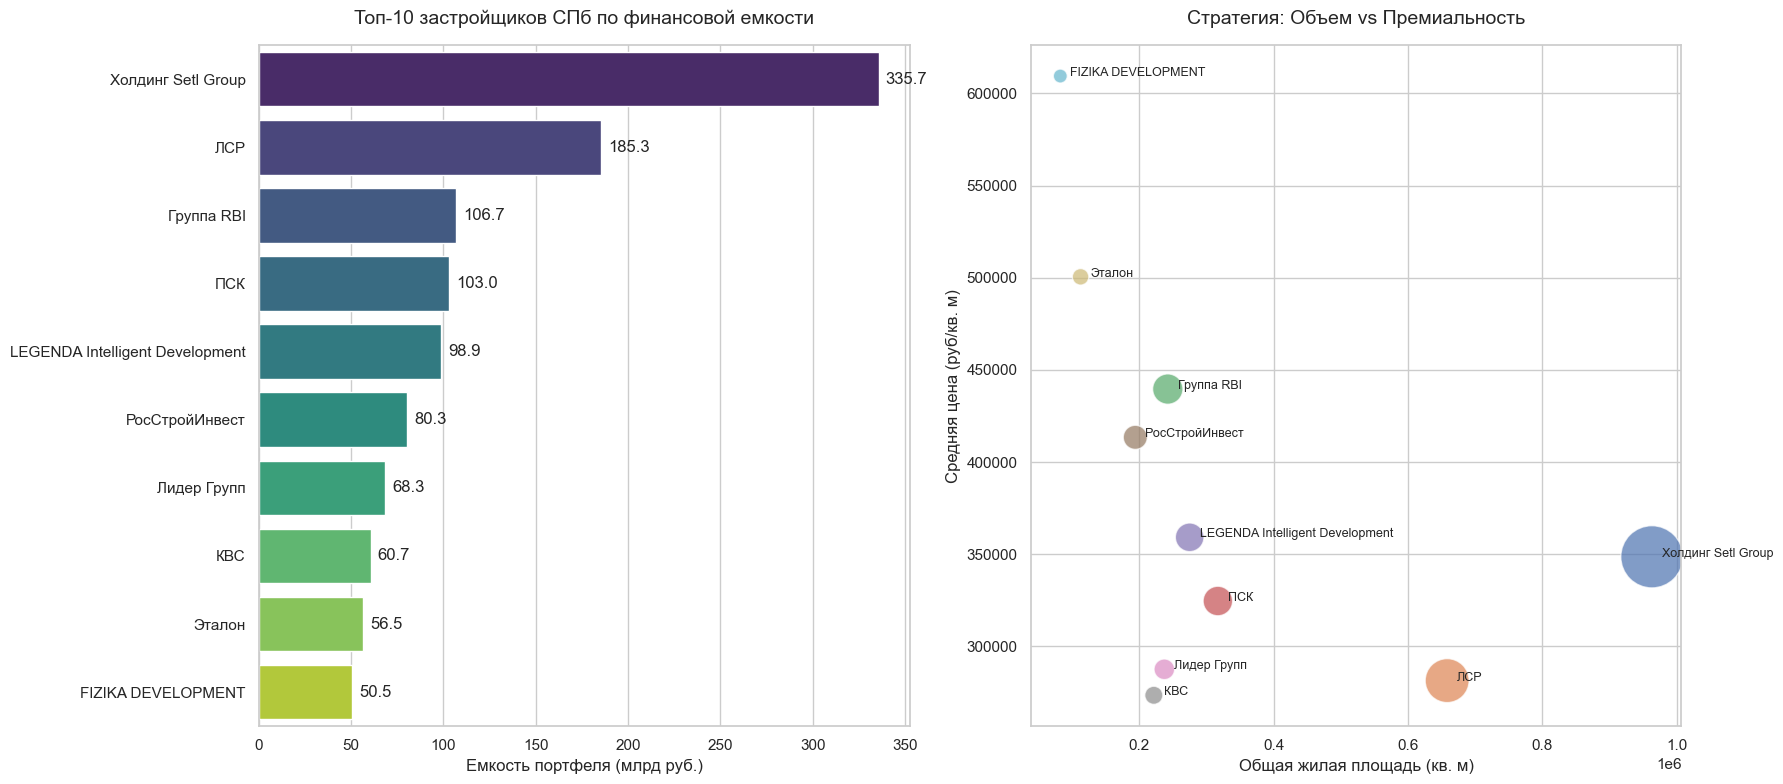

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных (замените имя файла, если вы сохраняли агрегацию в CSV)
# Для этого скрипта предполагается, что вы сохранили предыдущий вывод в market_analytics_spb.csv
df = market_analytics.copy()  # Используем DataFrame из предыдущего шага
top_10 = df.head(10).copy()

# Настройка стиля
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif' # Для корректного отображения кириллицы (на WSL может потребоваться установка шрифтов)

# Создаем фигуру с двумя графиками (1 строка, 2 колонки)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# График 1: Финансовая емкость портфеля (Bar chart)
sns.barplot(
    data=top_10, 
    y='Застройщик', 
    x='Емкость_портфеля_млрд_руб', 
    palette='viridis', 
    ax=ax1
)
ax1.set_title('Топ-10 застройщиков СПб по финансовой емкости', fontsize=14, pad=15)
ax1.set_xlabel('Емкость портфеля (млрд руб.)', fontsize=12)
ax1.set_ylabel('')
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.1f', padding=5)

# График 2: Стратегии девелоперов (Scatter plot)
sns.scatterplot(
    data=top_10, 
    x='Общая_жилая_площадь', 
    y='Средняя_цена_кв_м',
    size='Емкость_портфеля_млрд_руб', 
    sizes=(100, 2000), # Масштаб пузырьков
    alpha=0.7,
    hue='Застройщик',
    palette='deep',
    legend=False,
    ax=ax2
)

# Подписи точек на Scatter plot
for i in range(top_10.shape[0]):
    ax2.text(
        top_10['Общая_жилая_площадь'].iloc[i] + 15000, 
        top_10['Средняя_цена_кв_м'].iloc[i], 
        top_10['Застройщик'].iloc[i], 
        fontsize=9
    )

ax2.set_title('Стратегия: Объем vs Премиальность', fontsize=14, pad=15)
ax2.set_xlabel('Общая жилая площадь (кв. м)', fontsize=12)
ax2.set_ylabel('Средняя цена (руб/кв. м)', fontsize=12)

# Сохранение и вывод
plt.tight_layout()
plt.savefig('spb_real_estate_analysis.png', dpi=300, bbox_inches='tight')
print("Графики сохранены в файл 'spb_real_estate_analysis.png'")